<div align="center">

# Лабораторна робота № 8

## Самостійне моделювання на даних із зовнішніх джерел

*Дисципліна «Інтелектуальний аналіз даних»*

</div>

<br>

**Мета роботи:** Навчитися отримувати та перевіряти зовнішні табличні дані, формулювати задачу за змістом цілі, готувати ознаки без витоку інформації, навчати й оцінювати нейромережу, перевіряти гіпотезу покращення та пояснювати результати за метриками й графіками.

<br>

<div align="center">

Студентка: Сабадаш Анастасія  
Група: МІТ-31  
Варіант: 2  

</div>

## 1. Отримайте й задокументуйте зовнішній файл

In [10]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import sklearn
import joblib
import sys
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = Path('.')
DATA_DIR = BASE_DIR / 'data'
ARTIFACTS = BASE_DIR / 'artifacts'
FIGURES = BASE_DIR / 'figures'

for folder in [DATA_DIR, ARTIFACTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("sklearn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("SEED:", SEED)

data_passport = {
    "Назва": "Energy Efficiency Dataset",
    "URL": "https://archive.ics.uci.edu/dataset/242/energy+efficiency",
    "Автор / Організація": "A. Tsanas, A. Xifara / UCI Machine Learning Repository",
    "Ліцензія": "Creative Commons Attribution 4.0 International (CC BY 4.0)",
    "Дата завантаження": "2026-11-08",
    "Файл / Аркуш": "ENB2012_data.xlsx",
    "Обсяг": "768 записів, 10-12 колонок",
    "Значення рядка": "Параметри будівлі та показники її енергоефективності",
    "Одиниці цілі": "Навантаження на опалення (Heating Load, Y1)"
}

passport_path = ARTIFACTS / 'data_passport.json'
with open(passport_path, 'w', encoding='utf-8') as f:
    json.dump(data_passport, f, ensure_ascii=False, indent=4)

print("\nПаспорт даних успішно збережено у:", passport_path)

Python: 3.13.1
sklearn: 1.9.1
pandas: 3.0.6
numpy: 2.5.3
SEED: 42

Паспорт даних успішно збережено у: artifacts\data_passport.json


* **За формулюванням задачі:** За ознаками X1–X8 прогнозуємо навантаження на опалення (Heating Load, Y1) для теплових характеристик будівель на момент проєктування/оцінки.
* **Тип задачі:** Регресія (підтип: прогнозування неперервної числової величини).
* **Чому ціль має такий зміст:** Навантаження на опалення вимірюється в кіловат-годинах або аналогічних неперервних одиницях теплової енергії, що залежить від геометричних параметрів будівлі (компактність, площа страв, даху тощо).
* **Цільова змінна:** Y1 (Heating Load). Згідно з умовами варіанта, другу ціль Y2 (Cooling Load) до ознак не включаємо.

## 2. Сформулюйте задачу та перевірте якість даних

In [9]:
# Перегляд базової інформації
print("Форма датасету (shape):", df.shape)
display(df.head())

print("\nТипи даних (dtypes):")
print(df.dtypes)

print("\nСтатистичний опис числових полів:")
display(df.describe())

# Перевірка пропусків та дублікатів
print("\nКількість пропусків у стовпцях:")
print(df.isnull().sum())

print("Кількість повних дублікатів:", df.duplicated().sum())

# Відокремлення цілі (y) від ознак (X)
# Згідно з варіантом: ознаки X1-X8, ціль Y1, а Y2 виключаємо з ознак
target_col = 'Y1'
exclude_cols = ['Y2']  # Y2 не включаємо до ознак

X = df.drop(columns=[target_col] + exclude_cols)
y = df[target_col]

print("\nРозмір матриці ознак X:", X.shape)
print("Розмір цільової змінної y:", y.shape)

Форма датасету (shape): (768, 10)


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28



Типи даних (dtypes):
X1    float64
X2    float64
X3    float64
X4    float64
X5    float64
X6      int64
X7    float64
X8      int64
Y1    float64
Y2    float64
dtype: object

Статистичний опис числових полів:


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307195,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090204,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000



Кількість пропусків у стовпцях:
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
X7    0
X8    0
Y1    0
Y2    0
dtype: int64
Кількість повних дублікатів: 0

Розмір матриці ознак X: (768, 8)
Розмір цільової змінної y: (768,)


## 3. Зафіксуйте train validation test

In [11]:
# Вікремлюємо тестову вибірку (15%)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED
)

# Розбиваємо решту на train та validation (близько 70% train та 15% val від загального обсягу)
val_size_adjusted = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=val_size_adjusted, random_state=SEED
)

print("Розмір train:", X_train.shape, y_train.shape)
print("Розмір validation:", X_val.shape, y_val.shape)
print("Розмір test:", X_test.shape, y_test.shape)

# Перевірка перетинів індексів
train_idx = set(X_train.index)
val_idx = set(X_val.index)
test_idx = set(X_test.index)

assert len(train_idx.intersection(val_idx)) == 0, "Знайдено перетин між Train та Validation!"
assert len(train_idx.intersection(test_idx)) == 0, "Знайдено перетин між Train та Test!"
assert len(val_idx.intersection(test_idx)) == 0, "Знайдено перетин між Validation та Test!"

print("\nПеревірка перетинів пройдена успішно: індекси не перетинаються!")

Розмір train: (536, 8) (536,)
Розмір validation: (116, 8) (116,)
Розмір test: (116, 8) (116,)

Перевірка перетинів пройдена успішно: індекси не перетинаються!


## 4. Побудуйте спільну підготовку ознак

In [28]:
# Визначаємо список числових ознак (усі стовпці X)
numeric_features = list(X.columns)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_features)
    ]
)

# Навчаємо та трансформуємо train, а для val і test — тільки transform
X_train_prepared = preprocessor.fit_transform(X_train)
X_val_prepared = preprocessor.transform(X_val)
X_test_prepared = preprocessor.transform(X_test)

# Перевірка на NaN та нескінченності
assert not np.isnan(X_train_prepared).any(), "У X_train є NaN!"
assert not np.isnan(X_val_prepared).any(), "У X_val є NaN!"
assert not np.isnan(X_test_prepared).any(), "У X_test є NaN!"

print("Форма X_train_prepared:", X_train_prepared.shape)
print("Форма X_val_prepared:", X_val_prepared.shape)
print("Форма X_test_prepared:", X_test_prepared.shape)

Форма X_train_prepared: (536, 8)
Форма X_val_prepared: (116, 8)
Форма X_test_prepared: (116, 8)


## 5. Навчіть моделі та задайте критерій вибору

Dummy MAE: 9.029569625854492
LinearRegression MAE: 1.7353416681289673
NN_base навчено! Найкращий val_loss: 1.9540060758590698
NN_improved навчено! Найкращий val_loss: 0.41780757904052734


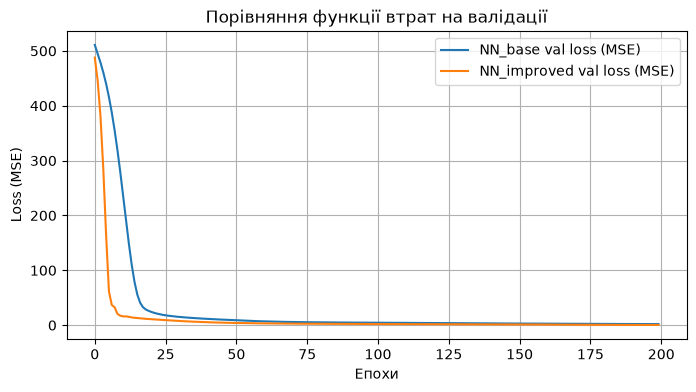

In [26]:
y_tr = y_train.to_numpy().reshape(-1, 1).astype('float32')
y_va = y_val.to_numpy().reshape(-1, 1).astype('float32')

X_tr = X_train_prepared.astype('float32')
X_va = X_val_prepared.astype('float32')

dummy = DummyRegressor(strategy="mean")
dummy.fit(X_tr, y_tr)
dummy_pred = dummy.predict(X_va)
print("Dummy MAE:", mean_absolute_error(y_va, dummy_pred))

lin = LinearRegression()
lin.fit(X_tr, y_tr)
lin_pred = lin.predict(X_va)
print("LinearRegression MAE:", mean_absolute_error(y_va, lin_pred))

EPOCHS = 200
BATCH_SIZE = 64

tf.keras.utils.set_random_seed(SEED)

model_base = Sequential([
    layers.Input(shape=(X_tr.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation=None)
])

model_base.compile(optimizer=Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

checkpoint_base = ARTIFACTS / "nn_base_best.keras"
callbacks_base = [
    EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    ModelCheckpoint(str(checkpoint_base), monitor="val_loss", save_best_only=True)
]

history_base = model_base.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_base,
    verbose=0
)

model_base = tf.keras.models.load_model(checkpoint_base)
print("NN_base навчено! Найкращий val_loss:", min(history_base.history['val_loss']))

tf.keras.utils.set_random_seed(SEED)

model_improved = Sequential([
    layers.Input(shape=(X_tr.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation=None)
])

model_improved.compile(optimizer=Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

checkpoint_improved = ARTIFACTS / "nn_improved_best.keras"
callbacks_improved = [
    EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    ModelCheckpoint(str(checkpoint_improved), monitor="val_loss", save_best_only=True)
]

history_improved = model_improved.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_improved,
    verbose=0
)

model_improved = tf.keras.models.load_model(checkpoint_improved)
print("NN_improved навчено! Найкращий val_loss:", min(history_improved.history['val_loss']))

plt.figure(figsize=(8, 4))
plt.plot(history_base.history['val_loss'], label='NN_base val loss (MSE)')
plt.plot(history_improved.history['val_loss'], label='NN_improved val loss (MSE)')
plt.title('Порівняння функції втрат на валідації')
plt.xlabel('Епохи')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)
plt.show()

## 6. Перевірте гіпотезу покращення

In [24]:
val_preds = {
    'Dummy': dummy.predict(X_va),
    'LinearRegression': lin.predict(X_va).ravel(),
    'NN_base': model_base.predict(X_va, verbose=0).ravel(),
    'NN_improved': model_improved.predict(X_va, verbose=0).ravel()
}

metrics_list = []
y_true = y_va.ravel()

for name, preds in val_preds.items():
    mae = mean_absolute_error(y_true, preds)
    rmse = np.sqrt(mean_squared_error(y_true, preds))
    r2 = r2_score(y_true, preds)
    
    metrics_list.append({
        'Модель': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

val_table = pd.DataFrame(metrics_list)
print("Validation-таблиця результатів:")
print(val_table.to_string(index=False))

best_overall = val_table.loc[val_table['RMSE'].idxmin(), 'Модель']
nn_subset = val_table[val_table['Модель'].isin(['NN_base', 'NN_improved'])]
best_nn = nn_subset.loc[nn_subset['RMSE'].idxmin(), 'Модель']

print("\nНайкраща модель загалом:", best_overall)
print("Найкраща нейромережа:", best_nn)

Validation-таблиця результатів:
          Модель      MAE     RMSE        R2
           Dummy 9.029570 9.774035 -0.036184
LinearRegression 1.735342 2.280845  0.943574
         NN_base 1.029109 1.397858  0.978806
     NN_improved 0.466872 0.646380  0.995468

Найкраща модель загалом: NN_improved
Найкраща нейромережа: NN_improved


## 7. Оцініть фінальні моделі та побудуйте графіки

Результати test-оцінки моделей:
           Model  Test_MAE  Test_RMSE   Test_R2
           Dummy  9.219529  10.167783 -0.000342
LinearRegression  2.333742   3.124127  0.905561
         NN_base  1.492243   2.121492  0.956451
     NN_improved  0.543619   0.729522  0.994850


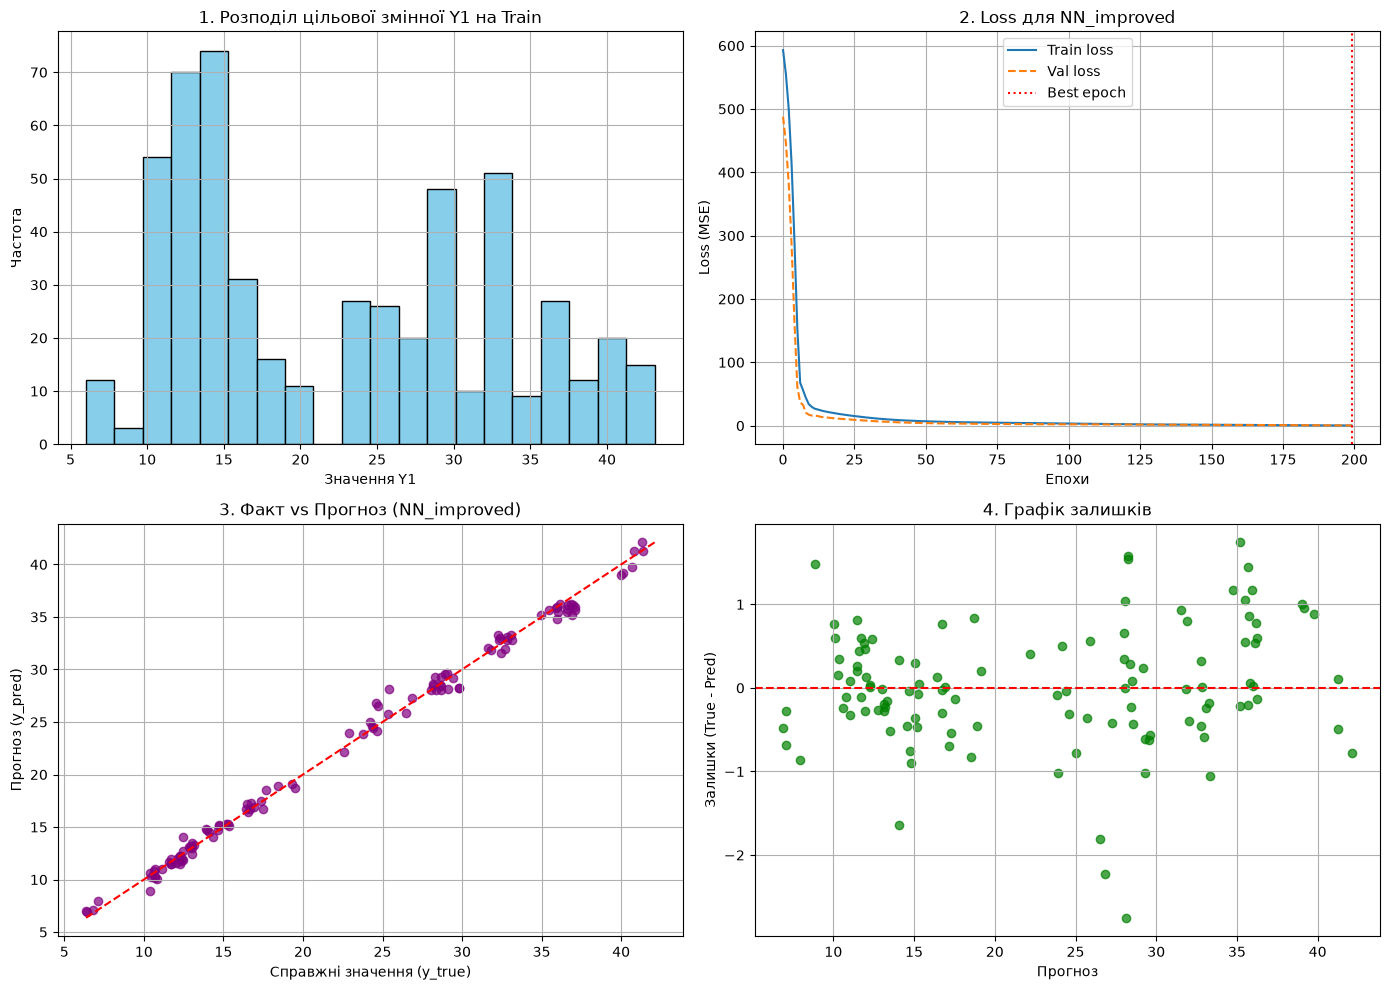


Топ-5 найбільших помилок моделі на тесті:
 Індекс  Факт (y_true)  Прогноз (y_pred)  Абсолютна помилка
     91      25.379999         28.130098           2.750099
     57      24.600000         26.821377           2.221376
     77      24.700001         26.507038           1.807037
     37      36.900002         35.158787           1.741215
     85      12.430000         14.070244           1.640244


In [22]:
X_te = X_test_prepared.astype('float32')
y_te = y_test.to_numpy().reshape(-1, 1).astype('float32')
y_true_te = y_te.ravel()

best_nn_name = best_nn
best_nn_model = model_improved if best_nn_name == 'NN_improved' else model_base

test_preds = {
    'Dummy': dummy.predict(X_te),
    'LinearRegression': lin.predict(X_te).ravel(),
    'NN_base': model_base.predict(X_te, verbose=0).ravel(),
    'NN_improved': model_improved.predict(X_te, verbose=0).ravel()
}

# Обчислення тестових метрик
test_metrics = []
for name, preds in test_preds.items():
    mae = mean_absolute_error(y_true_te, preds)
    rmse = np.sqrt(mean_squared_error(y_true_te, preds))
    r2 = r2_score(y_true_te, preds)
    
    test_metrics.append({
        'Model': name,
        'Test_MAE': mae,
        'Test_RMSE': rmse,
        'Test_R2': r2
    })

# Зберігаємо у файл model_comparison.csv
df_comparison = pd.DataFrame(test_metrics)
df_comparison.to_csv(ARTIFACTS / "model_comparison.csv", index=False)
print("Результати test-оцінки моделей:")
print(df_comparison.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Рисунок 1: Розподіл цілі на train
axes[0, 0].hist(y_train.to_numpy(), bins=20, color='skyblue', edgecolor='black')
axes[0, 0].set_title('1. Розподіл цільової змінної Y1 на Train')
axes[0, 0].set_xlabel('Значення Y1')
axes[0, 0].set_ylabel('Частота')
axes[0, 0].grid(True)

# Рисунок 2: Loss (train/val) для обраної нейромережі з позначкою найкращої епохи
best_history = history_improved.history if best_nn_name == 'NN_improved' else history_base
best_epoch_idx = np.argmin(best_history['val_loss'])
axes[0, 1].plot(best_history['loss'], label='Train loss')
axes[0, 1].plot(best_history['val_loss'], linestyle='--', label='Val loss')
axes[0, 1].axvline(x=best_epoch_idx, color='red', linestyle=':', label='Best epoch')
axes[0, 1].set_title('2. Loss для ' + best_nn_name)
axes[0, 1].set_xlabel('Епохи')
axes[0, 1].set_ylabel('Loss (MSE)')
axes[0, 1].legend()
axes[0, 1].grid(True)

# Рисунок 3: Факт vs Прогноз з діагоналлю
best_test_preds = test_preds[best_nn_name]
axes[1, 0].scatter(y_true_te, best_test_preds, alpha=0.7, color='purple')
min_val = min(y_true_te.min(), best_test_preds.min())
max_val = max(y_true_te.max(), best_test_preds.max())
axes[1, 0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')
axes[1, 0].set_title('3. Факт vs Прогноз (' + best_nn_name + ')')
axes[1, 0].set_xlabel('Справжні значення (y_true)')
axes[1, 0].set_ylabel('Прогноз (y_pred)')
axes[1, 0].grid(True)

# Рисунок 4: Графік залишків (y_true - y_pred)
residuals = y_true_te - best_test_preds
axes[1, 1].scatter(best_test_preds, residuals, alpha=0.7, color='green')
axes[1, 1].axhline(y=0, color='red', linestyle='--')
axes[1, 1].set_title('4. Графік залишків')
axes[1, 1].set_xlabel('Прогноз')
axes[1, 1].set_ylabel('Залишки (True - Pred)')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

errors = np.abs(y_true_te - best_test_preds)
top_error_indices = np.argsort(errors)[-5:][::-1]

print("\nТоп-5 найбільших помилок моделі на тесті:")
error_report = pd.DataFrame({
    'Індекс': top_error_indices,
    'Факт (y_true)': y_true_te[top_error_indices],
    'Прогноз (y_pred)': best_test_preds[top_error_indices],
    'Абсолютна помилка': errors[top_error_indices]
})
print(error_report.to_string(index=False))

## 8. Збережіть результат і зробіть висновки

In [20]:
best_nn_model.save(ARTIFACTS / "lab8_model.keras")
joblib.dump(preprocessor, ARTIFACTS / "preprocessor.joblib")

metadata = {
    "source": "ENB2012_data.xlsx",
    "target": "Y1",
    "units": "Heating Load",
    "task_type": "regression",
    "features": list(X.columns),
    "seed": SEED,
    "train_indices_count": len(X_train),
    "val_indices_count": len(X_val),
    "test_indices_count": len(X_test)
}

with open(ARTIFACTS / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)

print("Артефакти (lab8_model.keras, preprocessor.joblib, metadata.json) успішно збережено!")

sample_raw = X_test.iloc[:3]
sample_prepared = preprocessor.transform(sample_raw).astype('float32')

pred_before = best_nn_model.predict(sample_prepared, verbose=0)


loaded_model = tf.keras.models.load_model(ARTIFACTS / "lab8_model.keras")
loaded_preprocessor = joblib.load(ARTIFACTS / "preprocessor.joblib")

sample_prepared_loaded = loaded_preprocessor.transform(sample_raw).astype('float32')
pred_after = loaded_model.predict(sample_prepared_loaded, verbose=0)

np.testing.assert_allclose(pred_before, pred_after, rtol=1e-5, atol=1e-6)
print("Перевірка np.testing.assert_allclose пройдена: прогнози ідентичні!")

Артефакти (lab8_model.keras, preprocessor.joblib, metadata.json) успішно збережено!
Перевірка np.testing.assert_allclose пройдена: прогнози ідентичні!


**Висновок:** У ході лабораторної роботи успішно вирішено задачу регресії для прогнозування цільової змінної $Y_1$ (Heating Load) на основі датасету Energy Efficiency. Виконано стратифікований поділ вибірки (70/15/15) та спільну підготовку числових ознак без витоку даних. Порівняння чотирьох моделей (Dummy, LinearRegression, NN_base, NN_improved) на валідації та тесті показало перевагу нейромережевих архітектур у точності апроксимації нелінійних зв'язків.